## 02\_rouen\_population\_options

# 02 · Population et offre de transport de la Métropole de Rouen

Préparation des données des objectifs 1 et 2.

1. **Population** : carreaux INSEE Filosofi de 200 m dont le centre se situe dans la Métropole Rouen Normandie.
2. **Offre de transport** : arrêts Astuce par mode (métro, TEOR, bus) desservis un jour ouvré de référence, gares TER, stations Lovélo. Les quais de même nom distants de moins de 150 m forment un seul lieu d'arrêt.
3. **Carreaux candidats à un nouvel arrêt** : carreaux à moins de 100 m d'un tronçon de ligne de bus, le tronçon étant approché par le segment entre deux arrêts consécutifs.

**Sorties :** tables `carreaux_rouen`, `options_rouen`, `carreaux_sur_lignes` ; carte de contrôle `Files/traite/cartes/controle_rouen.png`.

In [ ]:
# 1. Dépendances
%pip install -q geopandas pyogrio py7zr

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 2. Outils communs
import os, re, glob, shutil, tempfile, zipfile, warnings
import numpy as np
import pandas as pd
from pyproj import Transformer
warnings.filterwarnings("ignore")

BASE = "/lakehouse/default/Files"
if not os.path.isdir(BASE):
    raise RuntimeError("Lakehouse par défaut non attaché : attacher le Lakehouse mobilite au notebook.")
BRUT = os.path.join(BASE, "brut")
TRAITE = os.path.join(BASE, "traite")
CARTES = os.path.join(TRAITE, "cartes")
os.makedirs(CARTES, exist_ok=True)

# Conversions entre systèmes de coordonnées : 3035 = grille INSEE, 2154 = Lambert-93 (mètres), 4326 = GPS
T_3035_2154 = Transformer.from_crs(3035, 2154, always_xy=True)
T_3035_4326 = Transformer.from_crs(3035, 4326, always_xy=True)
T_4326_3035 = Transformer.from_crs(4326, 3035, always_xy=True)
T_4326_2154 = Transformer.from_crs(4326, 2154, always_xy=True)

def _copier_csv(df, chemin):
    """Écrit le CSV en local, puis le copie dans le Lakehouse. Écrire directement dans OneLake échoue parfois
    quand le fichier existe déjà (« Unable to rename file »)."""
    fd, tmp = tempfile.mkstemp(suffix=".csv")
    os.close(fd)
    try:
        df.to_csv(tmp, index=False)
        if os.path.exists(chemin):
            os.remove(chemin)
        shutil.copyfile(tmp, chemin)
    finally:
        os.remove(tmp)

def _adresse_table(nom):
    """Adresse OneLake de la table dans le Lakehouse attaché, dans le schéma dbo s'il existe."""
    import notebookutils
    ctx = notebookutils.runtime.context
    espace = ctx.get("defaultLakehouseWorkspaceId") or ctx.get("currentWorkspaceId")
    lakehouse = ctx.get("defaultLakehouseId")
    if not (espace and lakehouse):
        raise RuntimeError("Lakehouse par défaut introuvable : attacher le Lakehouse mobilite au notebook")
    schema = "/dbo" if os.path.isdir("/lakehouse/default/Tables/dbo") else ""
    return f"abfss://{espace}@onelake.dfs.fabric.microsoft.com/{lakehouse}/Tables{schema}/{nom}"

def _ecrire_table(df, nom):
    """Table Delta lue par Power BI. Noyau Spark : saveAsTable. Noyau Python : bibliothèque deltalake."""
    try:
        spark  # n'existe que dans le noyau Spark
    except NameError:
        import pyarrow as pa
        import notebookutils
        from deltalake import write_deltalake
        donnees = pa.Table.from_pandas(df, preserve_index=False)
        options = {"bearer_token": notebookutils.credentials.getToken("storage"), "use_fabric_endpoint": "true"}
        try:
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", schema_mode="overwrite",
                            storage_options=options)
        except TypeError:   # anciennes versions de deltalake
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", overwrite_schema=True,
                            storage_options=options)
        return
    spark.createDataFrame(df).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nom)

def enregistrer(df, nom):
    """Enregistre un tableau en CSV dans Files/traite (relu par les autres notebooks)
    et en table du Lakehouse (lue par Power BI), avec le noyau Python comme avec le noyau Spark."""
    df = df.reset_index(drop=True).copy()
    _copier_csv(df, os.path.join(TRAITE, nom + ".csv"))
    for c in df.columns:
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])):
            df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    try:
        _ecrire_table(df, nom)
        print(f"   table {nom} : {len(df)} lignes (copie dans Files/traite/{nom}.csv)")
    except Exception as e:
        print(f"   {nom}.csv : {len(df)} lignes. ATTENTION, table non créée pour Power BI : {e}")

def nb(n):
    """Écrit un nombre avec des espaces entre les milliers : 12 345."""
    return f"{n:,.0f}".replace(",", " ")

def lire(nom):
    """Relit un tableau enregistré par un autre notebook."""
    chemin = os.path.join(TRAITE, nom + ".csv")
    if not os.path.exists(chemin):
        raise FileNotFoundError(f"{nom}.csv introuvable dans Files/traite : exécuter d'abord le notebook qui le produit.")
    return pd.read_csv(chemin, dtype={"idcar": str, "commune": str, "idcar_1km": str, "candidat": str})

COLONNES_FILOSOFI = ["idcar_200m", "idcar_1km", "i_est_200", "lcog_geo", "ind", "men", "men_pauv", "men_1ind",
                     "men_5ind", "men_prop", "men_fmp", "ind_snv", "men_surf", "men_coll", "men_mais", "log_av45",
                     "log_45_70", "log_70_90", "log_ap90", "log_inc", "log_soc", "ind_0_3", "ind_4_5", "ind_6_10",
                     "ind_11_17", "ind_18_24", "ind_25_39", "ind_40_54", "ind_55_64", "ind_65_79", "ind_80p", "ind_inc"]
TEXTE_FILOSOFI = ["idcar_200m", "idcar_1km", "lcog_geo"]

def charger_filosofi():
    """Carreaux de 200 m de métropole (CSV ou GeoPackage), avec leur centre en coordonnées 3035."""
    csvs = sorted(glob.glob(os.path.join(BRUT, "filosofi", "**", "*.csv"), recursive=True),
                  key=os.path.getsize, reverse=True)
    csvs = [c for c in csvs if "met" in os.path.basename(c).lower()] or csvs
    if csvs:
        source = csvs[0]
        with open(source, encoding="utf-8", errors="replace") as f:
            entete = f.readline()
        sep = ";" if entete.count(";") > entete.count(",") else ","
        noms = [c.strip().strip('"') for c in entete.strip().split(sep)]
        utiles = [c for c in noms if c.lower() in COLONNES_FILOSOFI]
        df = pd.read_csv(source, sep=sep, usecols=utiles,
                         dtype={c: str for c in utiles if c.lower() in TEXTE_FILOSOFI})
    else:
        gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
                 if "carreaux" in os.path.basename(g).lower() and "met" in os.path.basename(g).lower()]
        if not gpkgs:
            raise FileNotFoundError("Carreaux Filosofi introuvables dans Files/brut/filosofi (notebook 01).")
        import pyogrio
        source = gpkgs[0]
        df = pyogrio.read_dataframe(source, read_geometry=False)
    df.columns = [c.lower() for c in df.columns]
    df = df[[c for c in COLONNES_FILOSOFI if c in df.columns]].copy()
    for c in df.columns:
        if c not in TEXTE_FILOSOFI and not pd.api.types.is_numeric_dtype(df[c]):   # décimales avec une virgule
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    nombres = [c for c in df.columns if c not in TEXTE_FILOSOFI]
    df[nombres] = df[nombres].fillna(0)
    # L'identifiant INSPIRE donne le coin sud-ouest du carreau en mètres : CRS3035RES200mN<nord>E<est>
    ne = df["idcar_200m"].astype(str).str.extract(r"CRS3035RES200mN(\d+)E(\d+)").astype(float)
    df["x3035"], df["y3035"] = ne[1] + 100, ne[0] + 100
    df = df.dropna(subset=["x3035", "y3035"])
    df["ix"] = ((df["x3035"] - 100) // 200).astype("int64")
    df["iy"] = ((df["y3035"] - 100) // 200).astype("int64")
    df["commune"] = df["lcog_geo"].astype(str).str[:5]
    df = df.rename(columns={"idcar_200m": "idcar"}).reset_index(drop=True)
    print(f"Filosofi : {nb(len(df))} carreaux de métropole lus ({os.path.basename(source)})")
    return df

def trouver_admin_express():
    """GeoPackage ADMIN EXPRESS : déjà extrait, ou extrait de l'archive .7z déposée dans Files/brut."""
    gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
             if "ADE" in os.path.basename(g).upper() or "ADMIN" in os.path.basename(g).upper()]
    if gpkgs:
        return gpkgs[0]
    archives = [a for a in glob.glob(os.path.join(BRUT, "**", "*.7z"), recursive=True) if "ADMIN" in a.upper()]
    if not archives:
        raise FileNotFoundError("Contours introuvables : fichiers IGN du notebook 01 ou archive ADMIN-EXPRESS (.7z) attendus dans Files/brut.")
    import py7zr
    with py7zr.SevenZipFile(sorted(archives)[-1], "r") as z:
        z.extractall(os.path.join(BRUT, "ign"))
    return trouver_admin_express()

def charger_territoire(court, mot):
    """Contour de l'intercommunalité (Lambert-93) et ses communes."""
    import geopandas as gpd
    f_epci = os.path.join(BRUT, f"epci_{court}.geojson")
    f_communes = os.path.join(BRUT, f"communes_{court}.geojson")
    if os.path.exists(f_epci) and os.path.exists(f_communes):
        epci = gpd.read_file(f_epci).to_crs(2154)
        communes = gpd.read_file(f_communes).to_crs(2154)
    else:
        gpkg = trouver_admin_express()
        epci = gpd.read_file(gpkg, layer="epci")
        epci = epci[epci["nom_officiel"].str.contains(mot, case=False, na=False)].to_crs(2154)
        siren = str(epci.iloc[0]["code_siren"])
        communes = gpd.read_file(gpkg, layer="commune")
        communes = communes[communes["codes_siren_des_epci"].astype(str).str.contains(siren, na=False)].to_crs(2154)
    contour = epci.geometry.iloc[0]
    communes = communes[["code_insee", "nom_officiel", "geometry"]].rename(
        columns={"code_insee": "commune", "nom_officiel": "commune_nom"})
    print(f"{epci.iloc[0]['nom_officiel']} : {len(communes)} communes, {contour.area / 1e6:.0f} km²")
    return contour, communes

def dans_contour(contour, x, y):
    """Vrai pour les points (Lambert-93) situés dans le contour."""
    import shapely
    xmin, ymin, xmax, ymax = contour.bounds
    resultat = np.zeros(len(x), dtype=bool)
    cadre = (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax)
    shapely.prepare(contour)
    resultat[cadre] = shapely.contains_xy(contour, x[cadre], y[cadre])
    return resultat

In [ ]:
# 3. Contour de la Métropole et carreaux INSEE qui s'y trouvent
contour, communes = charger_territoire("rouen", "Rouen")
fil = charger_filosofi()
fil["x"], fil["y"] = T_3035_2154.transform(fil["x3035"].values, fil["y3035"].values)
carreaux = fil[dans_contour(contour, fil["x"].values, fil["y"].values)].copy()
carreaux["lon"], carreaux["lat"] = T_3035_4326.transform(carreaux["x3035"].values, carreaux["y3035"].values)
noms = dict(zip(communes["commune"], communes["commune_nom"]))
carreaux["commune_nom"] = carreaux["commune"].map(noms).fillna("Autre commune")
carreaux["population"] = carreaux["ind"]
carreaux["niveau_vie_moyen"] = np.where(carreaux["ind"] > 0, carreaux["ind_snv"] / carreaux["ind"].clip(lower=1), 0).round(0)
del fil

print(f"Carreaux habités dans la Métropole : {len(carreaux)}")
print(f"Population totale : {nb(carreaux['population'].sum())} habitants")
print(f"Carreaux aux valeurs estimées par l'INSEE (moins de 11 ménages) : {int(carreaux['i_est_200'].sum())}")
print(f"Communes représentées : {carreaux['commune'].nunique()}")

Métropole Rouen Normandie : 71 communes, 664 km²
Filosofi : 2 298 582 carreaux de métropole lus (carreaux_200m_met.csv)
Carreaux habités dans la Métropole : 5727
Population totale : 453 452 habitants
Carreaux aux valeurs estimées par l'INSEE (moins de 11 ménages) : 2662
Communes représentées : 76


In [ ]:
# 4. Arrêts du réseau Astuce (GTFS) : regroupement des quais, type d'arrêt, passages par jour
from datetime import date, timedelta
from scipy.cluster.hierarchy import fcluster, linkage

def lire_gtfs(chemin):
    z = zipfile.ZipFile(chemin)
    def table(nom, colonnes=None):
        noms = [n for n in z.namelist() if n.split("/")[-1] == nom]
        if not noms:
            return None
        df = pd.read_csv(z.open(noms[0]), dtype=str, encoding="utf-8-sig", usecols=colonnes)
        df.columns = [c.strip() for c in df.columns]
        return df
    return {
        "stops": table("stops.txt"), "routes": table("routes.txt"), "trips": table("trips.txt"),
        "stop_times": table("stop_times.txt", lambda c: c.strip() in ("trip_id", "stop_id", "stop_sequence")),
        "calendar": table("calendar.txt"), "calendar_dates": table("calendar_dates.txt"),
    }

def services_du_jour(g, jour):
    actifs, d = set(), jour.strftime("%Y%m%d")
    nom_jour = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"][jour.weekday()]
    cal, exc = g["calendar"], g["calendar_dates"]
    if cal is not None and len(cal):
        ok = (cal["start_date"] <= d) & (cal["end_date"] >= d) & (cal[nom_jour] == "1")
        actifs |= set(cal.loc[ok, "service_id"])
    if exc is not None and len(exc):
        ce_jour = exc[exc["date"] == d]
        actifs |= set(ce_jour.loc[ce_jour["exception_type"] == "1", "service_id"])
        actifs -= set(ce_jour.loc[ce_jour["exception_type"] == "2", "service_id"])
    return actifs

def jour_de_reference(g):
    """Le jour de semaine des 6 prochaines semaines où circulent le plus de services."""
    candidats = [date.today() + timedelta(days=k) for k in range(42)]
    if g["calendar_dates"] is not None:
        candidats += [date(int(d[:4]), int(d[4:6]), int(d[6:])) for d in g["calendar_dates"]["date"].unique()[:400]]
    candidats = [j for j in candidats if j.weekday() < 5]
    return max(candidats, key=lambda j: len(services_du_jour(g, j)))

def type_de_ligne(route_type, nom):
    nom = str(nom).strip().upper()
    if route_type in ("0", "1", "5", "7", "12") or nom in ("M", "METRO", "MÉTRO"):
        return "Métro"
    if re.fullmatch(r"T\d", nom):
        return "TEOR"
    if route_type == "2":
        return "Train"
    return "Bus"

g = lire_gtfs(os.path.join(BRUT, "gtfs_astuce.zip"))
jour = jour_de_reference(g)
services = services_du_jour(g, jour)
trajets = g["trips"][g["trips"]["service_id"].isin(services)][["trip_id", "route_id"]]
routes = g["routes"].copy()
for c in ["route_short_name", "route_long_name", "route_type"]:
    if c not in routes.columns:
        routes[c] = ""
routes["route_short_name"] = routes["route_short_name"].fillna("").where(routes["route_short_name"].fillna("") != "", routes["route_long_name"].fillna(""))
routes["type_ligne"] = [type_de_ligne(t, n) for t, n in zip(routes["route_type"].fillna("3"), routes["route_short_name"])]
passages = g["stop_times"].merge(trajets, on="trip_id").merge(routes[["route_id", "route_short_name", "type_ligne"]], on="route_id")
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
print(f"Jour de référence : {JOURS[jour.weekday()]} {jour:%d/%m/%Y}, {trajets['trip_id'].nunique()} courses ce jour-là")

arrets = g["stops"].copy()
arrets["location_type"] = arrets.get("location_type", pd.Series("0", index=arrets.index)).fillna("0").replace("", "0")
quais = arrets[arrets["location_type"] == "0"].copy()
quais["stop_lat"], quais["stop_lon"] = quais["stop_lat"].astype(float), quais["stop_lon"].astype(float)
quais["x"], quais["y"] = T_4326_2154.transform(quais["stop_lon"].values, quais["stop_lat"].values)
quais = quais[dans_contour(contour, quais["x"].values, quais["y"].values)]

# Un « lieu d'arrêt » = les quais de même nom à moins de 150 m les uns des autres (les deux sens d'une ligne)
quais["nom_norm"] = quais["stop_name"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
quais["lieu"] = ""
for nom, groupe in quais.groupby("nom_norm"):
    if len(groupe) == 1:
        quais.loc[groupe.index, "lieu"] = nom + "_1"
    else:
        etiquettes = fcluster(linkage(groupe[["x", "y"]].values, "single"), 150, "distance")
        quais.loc[groupe.index, "lieu"] = [f"{nom}_{e}" for e in etiquettes]

par_quai = passages.groupby("stop_id").agg(passages_jour=("trip_id", "size"))
lignes_quai = passages.groupby("stop_id").agg(lignes=("route_short_name", lambda s: sorted(set(s.dropna()))),
                                              types=("type_ligne", lambda s: set(s)))
quais = quais.join(par_quai, on="stop_id").join(lignes_quai, on="stop_id")
quais["passages_jour"] = quais["passages_jour"].fillna(0)
quais = quais[quais["passages_jour"] > 0]        # quai sans passage ce jour-là : ignoré

PRIORITE = ["Métro", "Train", "TEOR", "Bus"]
def type_du_lieu(ensembles):
    tous = set().union(*[e for e in ensembles if isinstance(e, set)])
    return next((t for t in PRIORITE if t in tous), "Bus")

bus = quais.groupby("lieu").agg(
    nom=("stop_name", "first"), x=("x", "mean"), y=("y", "mean"), passages_jour=("passages_jour", "sum"),
    lignes=("lignes", lambda l: ", ".join(sorted(set(sum([v for v in l if isinstance(v, list)], []))))),
    type=("types", type_du_lieu)).reset_index(drop=True)
print(f"Lieux d'arrêt Astuce desservis ce jour-là : {len(bus)}")
print(bus["type"].value_counts().to_string())

Jour de référence : vendredi 06/11/2026, 5754 courses ce jour-là
Lieux d'arrêt Astuce desservis ce jour-là : 1154
type
Bus      1053
TEOR       70
Métro      31


In [ ]:
# 5. Gares TER, depuis le fichier national des arrêts (lignes du réseau SNCF)
utiles = ["dataset_custom_title", "dataset_organisation", "stop_id", "stop_name", "stop_lat", "stop_lon", "location_type"]
entete = pd.read_csv(os.path.join(BRUT, "arrets_france.csv"), nrows=0)
nat = pd.read_csv(os.path.join(BRUT, "arrets_france.csv"), usecols=[c for c in utiles if c in entete.columns],
                  dtype=str, low_memory=False)
nat = nat.dropna(subset=["stop_lat", "stop_lon"])
for c in utiles:
    if c not in nat.columns:
        nat[c] = ""
sncf = nat[nat["dataset_custom_title"].fillna("").str.contains("SNCF", case=False)
           | nat["dataset_organisation"].fillna("").str.contains("SNCF", case=False)].copy()
if sncf["stop_id"].str.contains("Train", na=False).any():   # garde les quais de train, pas les cars TER
    sncf = sncf[sncf["stop_id"].str.contains("Train", na=False)]
sncf["x"], sncf["y"] = T_4326_2154.transform(sncf["stop_lon"].astype(float).values, sncf["stop_lat"].astype(float).values)
sncf = sncf[dans_contour(contour, sncf["x"].values, sncf["y"].values)]
sncf["nom_norm"] = sncf["stop_name"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
ter = sncf.groupby("nom_norm").agg(nom=("stop_name", "first"), x=("x", "mean"), y=("y", "mean")).reset_index(drop=True)
ter["type"], ter["lignes"], ter["passages_jour"] = "Gare TER", "TER", np.nan
del nat
print(f"Gares TER dans la Métropole : {len(ter)}")
print(", ".join(sorted(ter["nom"])))

Gares TER dans la Métropole : 8
Elbeuf - Saint-Aubin, Malaunay - Le Houlme, Maromme, Oissel, Rouen Rive Droite, Saint-Étienne-du-Rouvray, Sotteville, Tourville


In [ ]:
# 6. Stations de vélos Lovélo (flux GBFS du notebook 00)
lov = pd.read_csv(os.path.join(BRUT, "gbfs", "stations_lovelo.csv"))
lov["x"], lov["y"] = T_4326_2154.transform(lov["lon"].values, lov["lat"].values)
lov = lov[dans_contour(contour, lov["x"].values, lov["y"].values)]
velo = pd.DataFrame({"nom": lov["nom"], "x": lov["x"], "y": lov["y"], "type": "Vélo en libre-service",
                     "lignes": "Lovélo", "passages_jour": np.nan})
print(f"Stations Lovélo dans la Métropole : {len(velo)}")

Stations Lovélo dans la Métropole : 126


In [ ]:
# 7. Assembler les options et les enregistrer
import geopandas as gpd
options = pd.concat([bus, ter, velo], ignore_index=True)
options.insert(0, "option_id", [f"OPT{i:05d}" for i in range(len(options))])
options["lon"], options["lat"] = Transformer.from_crs(2154, 4326, always_xy=True).transform(options["x"].values, options["y"].values)
points = gpd.GeoDataFrame(options[["option_id"]], geometry=gpd.points_from_xy(options["x"], options["y"]), crs=2154)
options = options.merge(gpd.sjoin(points, communes, how="left")[["option_id", "commune", "commune_nom"]]
                        .drop_duplicates("option_id"), on="option_id", how="left")

colonnes_carreaux = ["idcar", "idcar_1km", "commune", "commune_nom", "lat", "lon", "x", "y", "ix", "iy", "population",
                     "ind", "men", "men_1ind", "men_coll", "men_prop", "log_soc", "ind_snv", "niveau_vie_moyen",
                     "ind_25_39", "ind_65_79", "ind_80p", "i_est_200"]
print("Enregistrement :")
enregistrer(carreaux[colonnes_carreaux], "carreaux_rouen")
enregistrer(options, "options_rouen")
print("\nOptions par type :")
print(options["type"].value_counts().to_string())

Enregistrement :
   table carreaux_rouen : 5727 lignes (copie dans Files/traite/carreaux_rouen.csv)
   table options_rouen : 1288 lignes (copie dans Files/traite/options_rouen.csv)

Options par type :
type
Bus                      1053
Vélo en libre-service     126
TEOR                       70
Métro                      31
Gare TER                    8


In [ ]:
# 8. Carreaux traversés par une ligne de bus Astuce (candidats pour un nouvel arrêt, notebook 20)
import shapely
ordre = g["stop_times"].merge(trajets, on="trip_id").merge(routes[["route_id", "type_ligne"]], on="route_id")
ordre = ordre[ordre["type_ligne"].isin(["Bus", "TEOR"])].copy()
ordre["stop_sequence"] = ordre["stop_sequence"].astype(int)
ordre = ordre.sort_values(["trip_id", "stop_sequence"])
ordre["suivant"] = ordre.groupby("trip_id")["stop_id"].shift(-1)
paires = ordre.dropna(subset=["suivant"])[["stop_id", "suivant"]].drop_duplicates()
pos = g["stops"].set_index("stop_id")[["stop_lon", "stop_lat"]].astype(float)
paires = paires[paires["stop_id"].isin(pos.index) & paires["suivant"].isin(pos.index)]
xa, ya = T_4326_2154.transform(pos.loc[paires["stop_id"], "stop_lon"].values, pos.loc[paires["stop_id"], "stop_lat"].values)
xb, yb = T_4326_2154.transform(pos.loc[paires["suivant"], "stop_lon"].values, pos.loc[paires["suivant"], "stop_lat"].values)
troncons = shapely.linestrings(np.stack([np.column_stack([xa, xb]), np.column_stack([ya, yb])], axis=-1))
arbre = shapely.STRtree(troncons)
centres = shapely.points(carreaux["x"].values, carreaux["y"].values)
idx_carreaux, _ = arbre.query(centres, predicate="dwithin", distance=100)
sur_lignes = carreaux.iloc[np.unique(idx_carreaux)][["idcar"]]
print(f"Tronçons de bus entre deux arrêts : {len(troncons)}")
print(f"Carreaux à moins de 100 m d'une ligne de bus : {len(sur_lignes)}")
enregistrer(sur_lignes, "carreaux_sur_lignes")

Tronçons de bus entre deux arrêts : 2761
Carreaux à moins de 100 m d'une ligne de bus : 2312
   table carreaux_sur_lignes : 2312 lignes (copie dans Files/traite/carreaux_sur_lignes.csv)


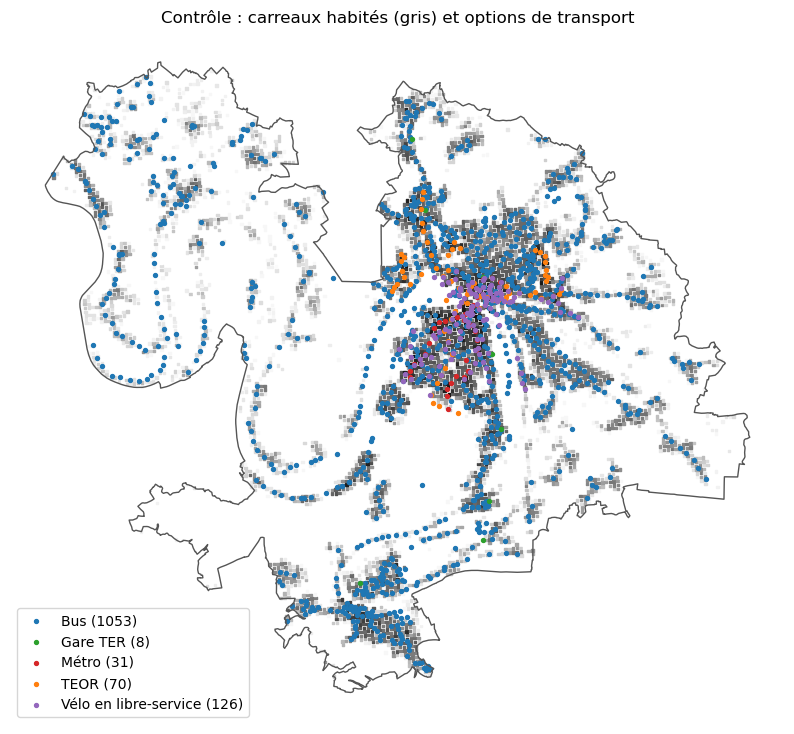

In [ ]:
# 9. Carte de contrôle (image enregistrée dans Files/traite/cartes/controle_rouen.png)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
gpd.GeoSeries([contour], crs=2154).boundary.plot(ax=ax, color="#555555", linewidth=1)
sc = ax.scatter(carreaux["x"], carreaux["y"], c=np.log10(carreaux["population"] + 1), s=3, cmap="Greys", marker="s")
couleurs = {"Métro": "#d62728", "TEOR": "#ff7f0e", "Bus": "#1f77b4", "Gare TER": "#2ca02c", "Vélo en libre-service": "#9467bd", "Train": "#2ca02c"}
for t, groupe in options.groupby("type"):
    ax.scatter(groupe["x"], groupe["y"], s=8, color=couleurs.get(t, "black"), label=f"{t} ({len(groupe)})")
ax.legend(loc="lower left")
ax.set_title("Contrôle : carreaux habités (gris) et options de transport")
ax.set_axis_off()
plt.savefig(os.path.join(CARTES, "controle_rouen.png"), dpi=120, bbox_inches="tight")
plt.show()